# **TP1 - Variable Types & Descriptive Statistics**

<b>Exploratory Data Analysis & Unsuperivsed Learning </b><br>
**Course: Dr. HAS Sothea** <br> 
**TP: Ms. UANN Sreyvi** <br>

-------

**Objective**: This initial practical session is designed to enhance your understanding of various data variable types and the corresponding statistical and graphical tools suitable for each type.

---------

> **The `Jupyter Notebook` for this TP can be downloaded here: [TP1-Gapminder](https://hassothea.github.io/I5_EDA_ITC/TPs/TP1_Variable_Types_Descriptive_Statistics.ipynb)**.

-------

# 1. `Gapminder` dataset

[`Gapminder`](https://pypi.org/project/gapminder/) is an excerpt of data available at [https://gapminder.org](https://www.gapminder.org/). For each of $142$ countries (`country`), the package provides values for life expectancy (`lifeExp`), GDP per capita (`gdpPercap`), and population (`pop`), every five years, from $1952$ to $2007$ (`year`). It is initially used in [Jennifer Bryan's excellent `gapminder` teaching package for R](https://github.com/jennybc/gapminder/) ([`ggplot`](https://ggplot2.tidyverse.org/), [`tidyverse`](https://www.tidyverse.org/), and more). For more information about `gapminder`: 
- Documentation: [https://www.gapminder.org/data/documentation/](https://www.gapminder.org/data/documentation/)
- A short demonstration video is available here: [Hans Rosling's 200 Countries, 200 Years, 4 Minutes - The Joy of Stats - BBC Four](https://youtu.be/jbkSRLYSojo?si=qipg08VIi999hEgo).

In [4]:
# useful packages
import numpy as np
import pandas as pd

%pip install gapminder  (for installing gapminder if you haven't had one)
from gapminder import gapminder
print(f"* Number of observations: {gapminder.shape[0]}")
gapminder.sample(3)

zsh:1: unmatched '
Note: you may need to restart the kernel to use updated packages.
* Number of observations: 1704


,country,continent,year,lifeExp,pop,gdpPercap
120,Benin,Africa,1952,38.223,1738315,1062.752200
1423,Spain,Europe,1987,76.900,38880702,15764.983130
979,Mauritius,Africa,1987,68.740,1042663,4783.586903


----------

# 2. Variable types

`EDA` involves summarizing and visualizing data to uncover patterns, detect anomalies, and understand relationships between variables. Statistical summaries, such as mean, median, and standard deviation, are essential tools in this process.

- Which variables are considered quantitative and which are qualitative? 

> Hint: You can check the default column types by using `gapminder.dtypes`. But this may not be accurate because some categorical data may be encoded using numerical values.

In [5]:
# TODO: variable types
gapminder.dtypes


country       object
continent     object
year           int64
lifeExp      float64
pop            int64
gdpPercap    float64
dtype: object

> **Your response**: 

## Qualitative : 

> **Country, Continent**

## Quantitative : 

> **Year, Pop , lifeExp and gdpPercap**



In [6]:
print(f"Quantitative variables: {gapminder.select_dtypes(include=[np.number]).columns.tolist()}")
print(f"Qualitative variables: {gapminder.select_dtypes(include=['object']).columns.tolist()}")

Quantitative variables: ['year', 'lifeExp', 'pop', 'gdpPercap']
Qualitative variables: ['country', 'continent']


## 2.1 Quantitative variables

1. In year 2002, 
- Compute suitable statistics for each quantitative variable (excluding `year`) to obtain an overall summary.
- Recall the definitions of **skewness** and **kurtosis** introduced in the course. 
- Compute these metrics for each quantitative variable and explain the distribution of each variable based on these values.

In [7]:
# TODO
gapminder_2002 = gapminder[gapminder['year'] == 2002]
gapminder_2002.sample(3)

gapminder_2002= gapminder_2002.select_dtypes(include=['int', 'float'])

# Summery statistics for quantitative variables in 2002
gapminder_2002[['lifeExp', 'gdpPercap', 'pop']].describe()


,lifeExp,gdpPercap,pop
count,142.000000,142.000000,1.420000e+02
mean,65.694923,9917.848365,4.145759e+07
std,12.279823,11154.114865,1.408483e+08
min,39.193000,241.165876,1.703720e+05
25%,55.522250,1409.567264,4.173506e+06
50%,70.825500,5319.804524,1.037292e+07
75%,75.459250,13359.512258,2.654556e+07
max,82.000000,44683.975250,1.280400e+09


In [8]:
# Calculate Skewness and Kurtosis for quantitative variables in 2002

from scipy.stats import skew , kurtosis

skewness_lifeExp = skew(gapminder_2002['lifeExp'])
kurtosis_lifeExp = kurtosis(gapminder_2002['lifeExp'])
skewness_gdpPercap = skew(gapminder_2002['gdpPercap'])
kurtosis_gdpPercap = kurtosis(gapminder_2002['gdpPercap'])
skewness_pop = skew(gapminder_2002['pop'])
kurtosis_pop = kurtosis(gapminder_2002['pop'])
print(f"Skewness of lifeExp: {skewness_lifeExp}")
print(f"Kurtosis of lifeExp: {kurtosis_lifeExp}")
print(f"Skewness of gdpPercap: {skewness_gdpPercap}")
print(f"Kurtosis of gdpPercap: {kurtosis_gdpPercap}")
print(f"Skewness of pop: {skewness_pop}")
print(f"Kurtosis of pop: {kurtosis_pop}")

Skewness of lifeExp: -0.6255988651087235
Kurtosis of lifeExp: -0.9635427928239317
Skewness of gdpPercap: 1.2453646790105017
Kurtosis of gdpPercap: 0.2884616043686923
Skewness of pop: 7.392404983560424
Kurtosis of pop: 57.4841237889041


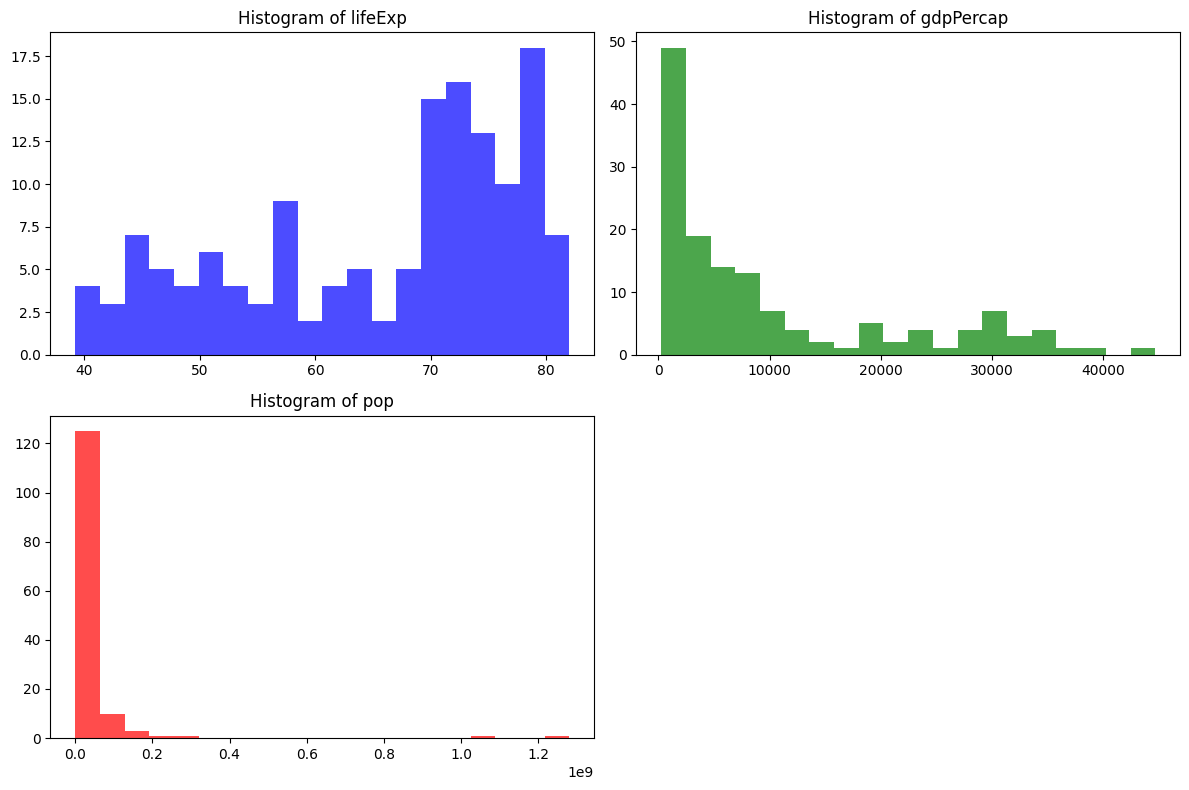

In [9]:
# Plot histograms  for quantitative variables in 2002
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.hist(gapminder_2002['lifeExp'], bins=20, color='blue', alpha=0.7)
plt.title('Histogram of lifeExp')
plt.subplot(2, 2, 2)
plt.hist(gapminder_2002['gdpPercap'], bins=20, color='green', alpha=0.7)
plt.title('Histogram of gdpPercap')
plt.subplot(2, 2, 3)
plt.hist(gapminder_2002['pop'], bins=20, color='red', alpha=0.7)
plt.title('Histogram of pop')
plt.tight_layout()

In [10]:
# Another Way to filter the data for the year 2002 using query method
data2002 = gapminder.query("year == 2002")
data2002.head(3)

,country,continent,year,lifeExp,pop,gdpPercap
10,Afghanistan,Asia,2002,42.129,25268405,726.734055
22,Albania,Europe,2002,75.651,3508512,4604.211737
34,Algeria,Africa,2002,70.994,31287142,5288.040382


2. Graphically represent the distribution of each variable for the year $2002$. After plotting the distributions, provide a brief explanation for each variable.

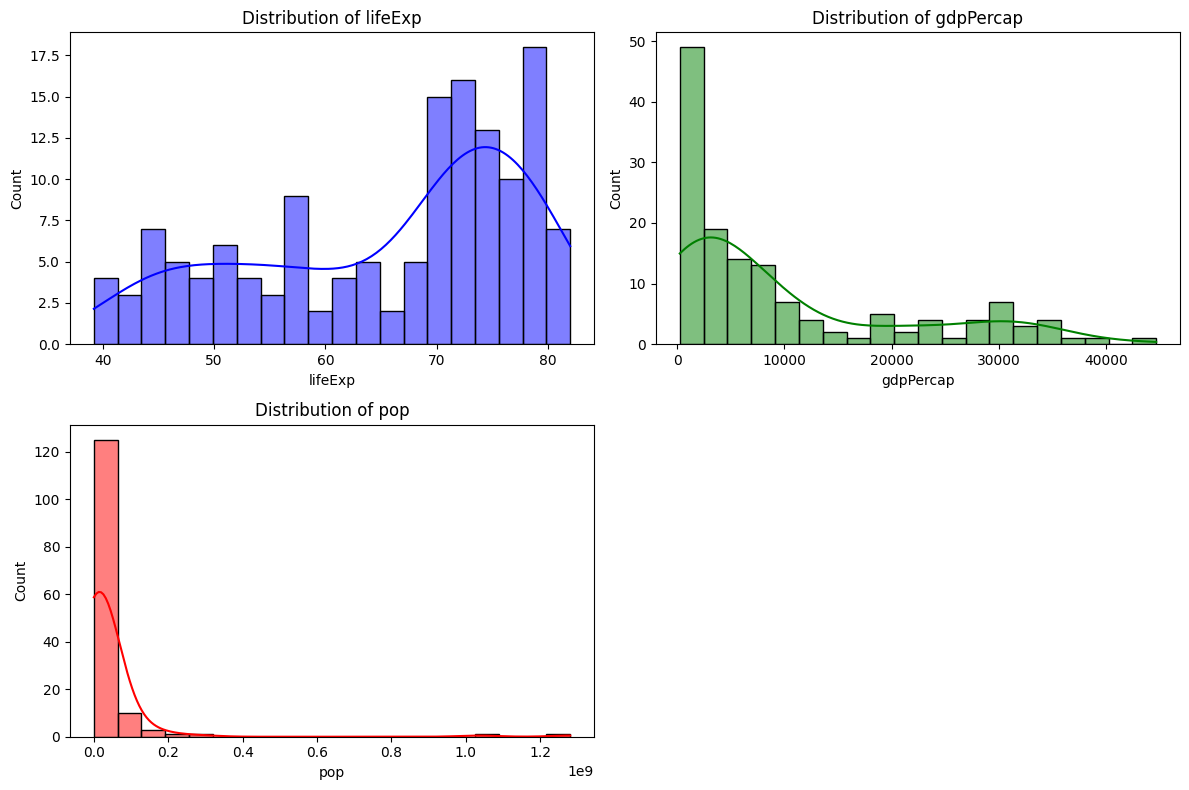

In [11]:
# TODO:
# Plot distribution of lifeExp, gdpPercap, and pop for the year 2002 using seaborn
import seaborn as sns
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
sns.histplot(data2002['lifeExp'], bins=20, color='blue', kde
=True)
plt.title('Distribution of lifeExp')
plt.subplot(2, 2, 2)
sns.histplot(data2002['gdpPercap'], bins=20, color='green'
, kde=True)
plt.title('Distribution of gdpPercap')
plt.subplot(2, 2, 3)
sns.histplot(data2002['pop'], bins=20, color='red', kde=True)
plt.title('Distribution of pop')
plt.tight_layout()  

In [12]:
import plotly.express as px

fig = px.histogram(data2002, x="lifeExp", nbins=20, title="Distribution of lifeExp")
fig.update_layout(width=800, height=400)
fig.update_traces(marker_color='blue', marker_line_color='black', marker_line_width=1.5, opacity=0.7)
fig.show()

### Explanation : lifeExp is around 70 to 80 for most country and it is skew to left

In [13]:
import plotly.express as px

fig = px.histogram(data2002, x="pop", nbins=20, title="Distribution of pop")
fig.update_layout(width=800, height=400)
fig.update_traces(marker_color='blue', marker_line_color='black', marker_line_width=1.5, opacity=0.7)
fig.show()

### most of country have population around 0 to 90M Yet other 10 country are in another bin 

In [14]:
import plotly.express as px

fig = px.histogram(data2002, x="gdpPercap", nbins=20, title="Distribution of gdpPercap")
fig.update_layout(width=800, height=400)
fig.update_traces(marker_color='blue', marker_line_color='black', marker_line_width=1.5, opacity=0.7)
fig.show()

### This distribution is skew to right and most of country have gpd 0 to 4990

3. According to the data, in 2002:
- Which country is the richest? 
- Which country is the poorest?
- Which country is the healthiest?
- Which country is the unhealthiest?

In [15]:
# TODO:

print(data2002.query("gdpPercap == gdpPercap.max()"))
data2002.query("gdpPercap == gdpPercap.min()")

     country continent  year  lifeExp      pop    gdpPercap
1150  Norway    Europe  2002    79.05  4535591  44683.97525


,country,continent,year,lifeExp,pop,gdpPercap
334,"Congo, Dem. Rep.",Africa,2002,44.966,55379852,241.165876


In [16]:
print(data2002.query("lifeExp == lifeExp.max()"))
print(data2002.query("lifeExp == lifeExp.min()"))

    country continent  year  lifeExp        pop   gdpPercap
802   Japan      Asia  2002     82.0  127065841  28604.5919
     country continent  year  lifeExp       pop    gdpPercap
1690  Zambia    Africa  2002   39.193  10595811  1071.613938


4. Repeat the previous question for the year 1977. Before computing, can you guess which country had the lowest life expectancy around that year?

In [17]:
# TODO:
gapminder.query("year == 1977").query("lifeExp == lifeExp.min()")


,country,continent,year,lifeExp,pop,gdpPercap
221,Cambodia,Asia,1977,31.22,6978607,524.972183


## 2.2. Qualitative variables

Qualitative variables are simpler than the quantitative ones, as we primarily focus on the proportion or frequency of each category. In our dataset, the existing qualitative variables are not suitable for analysis because they are repeated each year. Therefore, we will create three new qualitative variables associated with the three quantitative columns by copping them into three categories each.

In year 2002,

1. Add the following three variables to the `gapminder` dataset by grouping each quantitative variable into $3$ groups.
- Create variable `gdpQual` with three categories: [**"developing"**, **"moderate"**, **"developed"**] using variable `gdpPercap`.
- Create variable `popQual` with three categories: [**"small"**, **"medium"**, **"large"**] using variable `pop`.
- Create variable `lifeExpQual` with three categories: [**"unhealthy"**, **"moderate"**, **"healthy"**] using variable `lifeExp`.

> Hint: you may find `pd.cut` function helpful.

/var/folders/j0/kt7yx7x95r75nsbx5s3ldgt80000gn/T/ipykernel_31999/1158412972.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data2002['gdpQual'] = pd.cut(data2002['gdpPercap'], bins=3, labels=['Developing', 'Moderate', 'Developed'])
/var/folders/j0/kt7yx7x95r75nsbx5s3ldgt80000gn/T/ipykernel_31999/1158412972.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot = sns.catplot(x="gdpQual", kind="count", palette="pastel", data=data2002)


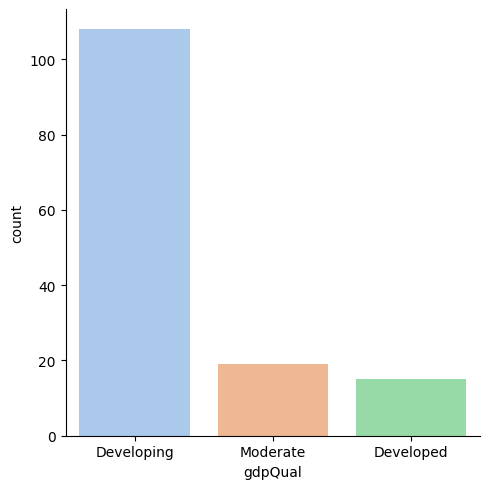

In [18]:
# TODO:
# Create Variable gdpQual with three categories: "Developed", "Developing", and "Moderate" based on gdpPercap values in 2002.

data2002['gdpQual'] = pd.cut(data2002['gdpPercap'], bins=3, labels=['Developing', 'Moderate', 'Developed'])

plot = sns.catplot(x="gdpQual", kind="count", palette="pastel", data=data2002)

popQual
Small     140
Large       2
Medium      0
Name: count, dtype: int64


/var/folders/j0/kt7yx7x95r75nsbx5s3ldgt80000gn/T/ipykernel_31999/2604427936.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data2002['popQual'] = pd.cut(data2002['pop'], bins=3, labels=['Small', 'Medium', 'Large'])
/var/folders/j0/kt7yx7x95r75nsbx5s3ldgt80000gn/T/ipykernel_31999/2604427936.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot = sns.catplot(x="popQual", kind="count", palette="pastel", data=data2002)


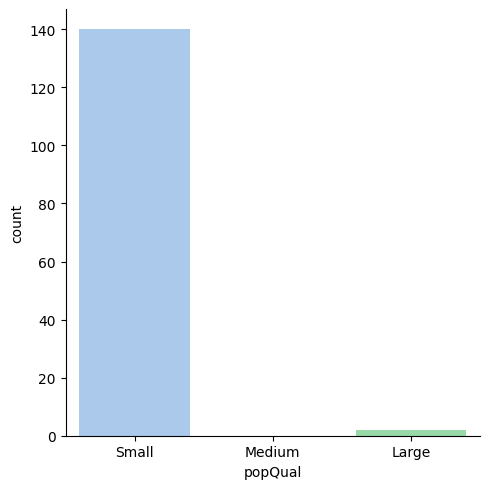

In [19]:
# TODO:
# Create Variable gdpQual with three categories: "Developed", "Developing", and "Moderate" based on gdpPercap values in 2002.

data2002['popQual'] = pd.cut(data2002['pop'], bins=3, labels=['Small', 'Medium', 'Large'])
print(data2002['popQual'].value_counts())
plot = sns.catplot(x="popQual", kind="count", palette="pastel", data=data2002)

/var/folders/j0/kt7yx7x95r75nsbx5s3ldgt80000gn/T/ipykernel_31999/1147525705.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data2002['lifeExpQual'] = pd.cut(data2002['lifeExp'], bins=3, labels=['Unhealthy', 'Moderate', 'Healthy'])
/var/folders/j0/kt7yx7x95r75nsbx5s3ldgt80000gn/T/ipykernel_31999/1147525705.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot = sns.catplot(x="lifeExpQual", kind="count", palette="pastel", data=data2002)


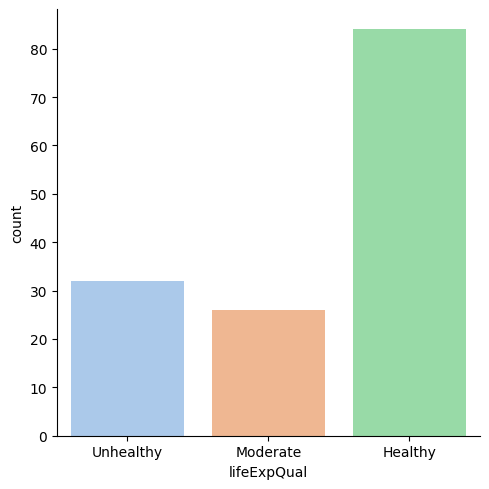

In [20]:
# TODO:
# Create Variable gdpQual with three categories: "Developed", "Developing", and "Moderate" based on gdpPercap values in 2002.

data2002['lifeExpQual'] = pd.cut(data2002['lifeExp'], bins=3, labels=['Unhealthy', 'Moderate', 'Healthy'])

plot = sns.catplot(x="lifeExpQual", kind="count", palette="pastel", data=data2002)

2. Compute the appropriate statistical values and graphically represent the distribution of each newly created qualitative variable.

In [21]:
# TODO
print(data2002['lifeExpQual'].value_counts())
print(data2002['popQual'].value_counts())
print(data2002['gdpQual'].value_counts())

lifeExpQual
Healthy      84
Unhealthy    32
Moderate     26
Name: count, dtype: int64
popQual
Small     140
Large       2
Medium      0
Name: count, dtype: int64
gdpQual
Developing    108
Moderate       19
Developed      15
Name: count, dtype: int64


- Graphically represent them and describe the graph.

In [22]:
# TODO


---------

# 3. Time evolution

`Gapminder` captures global changes from $1952$ to $2007$. It is more insightful to examine how these variables evolve over time.

## 3.1. Evolution of quantitative columns

1. Create a line plot of `lifeExp` for the five continents from $1952$ to $2007$ using `sns.lineplot`. What observations can you make from the plot?

<Axes: xlabel='year', ylabel='lifeExp'>

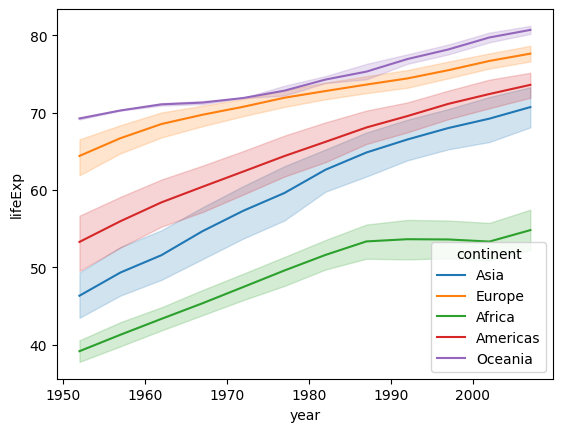

In [23]:
# To do
# Create line plot of lifeExp for five continents from 1952 to 2007 using sns.lineplot 
filtered_df = gapminder[gapminder['continent'].isin(['Asia', 'Europe', 'Africa', 'Americas', 'Oceania'])]

sns.lineplot(data=filtered_df, x='year', y='lifeExp', hue='continent')



2. Repeat the same process with `pop`, and then with `gdpPercap`. Provide your comments for each case.

<Axes: xlabel='year', ylabel='pop'>

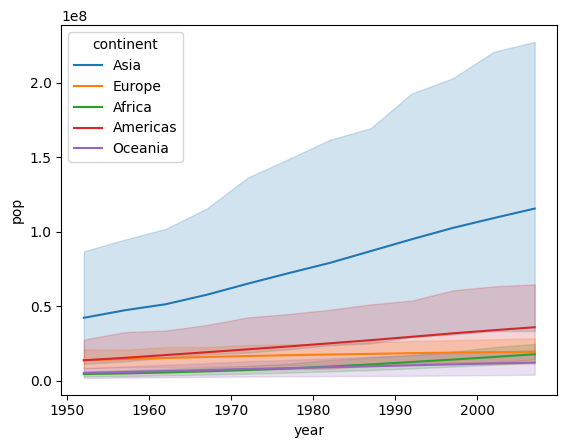

In [29]:
# To do
# Plot pop and gdpPercap for five continents from 1952 to 2007 using sns.lineplot
filtered_df = gapminder[gapminder['continent'].isin(['Asia', 'Europe', 'Africa', 'Americas', 'Oceania'])]
sns.lineplot(data=filtered_df, x='year', y='pop', hue='continent')



<Axes: xlabel='year', ylabel='gdpPercap'>

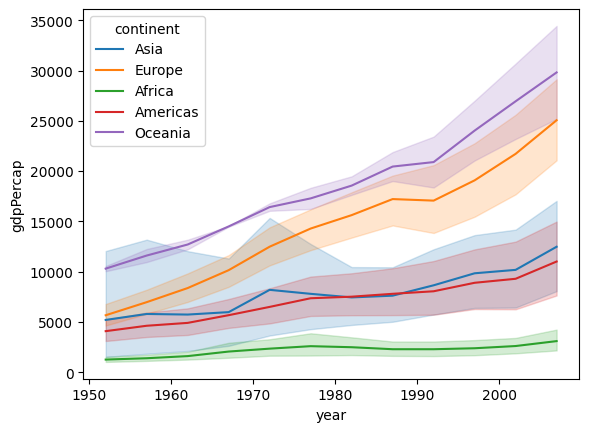

In [30]:
sns.lineplot(data=filtered_df, x='year', y='gdpPercap', hue='continent')

3. Plot the evolution of each of the three quantitative variables for **Cambodia** vs **Thailand**. Describe the graphs.

<Axes: xlabel='year', ylabel='lifeExp'>

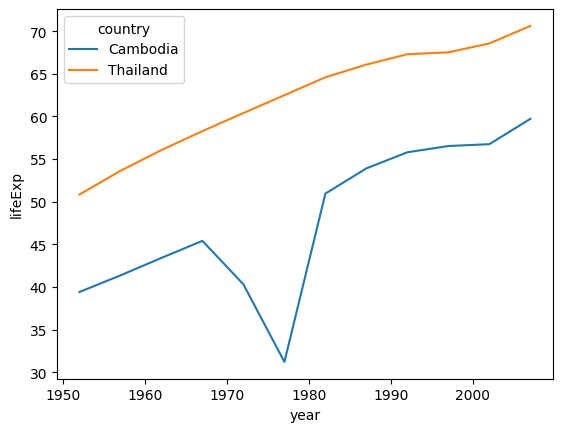

In [32]:
# To do
# PLot evolution of each of three quantitative variables (lifeExp, pop, gdpPercap) for Cambodia vs Thailand
data_cambodia_thailand = gapminder[gapminder['country'].isin(['Cambodia', 'Thailand'])]
sns.lineplot(data=data_cambodia_thailand, x='year', y='lifeExp', hue='country')


<Axes: xlabel='year', ylabel='pop'>

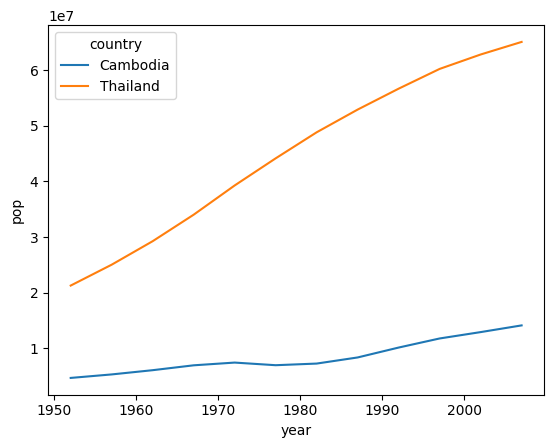

In [33]:
sns.lineplot(data=data_cambodia_thailand, x='year', y='pop', hue='country')


<Axes: xlabel='year', ylabel='gdpPercap'>

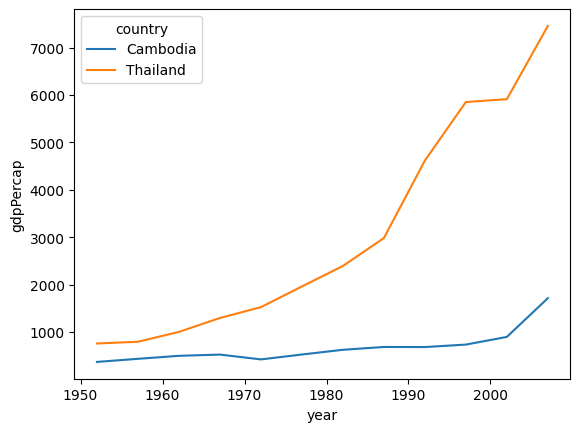

In [34]:
sns.lineplot(data=data_cambodia_thailand, x='year', y='gdpPercap', hue='country')

## 3.2. Evolution of qualitative columns

1. Visualize the evolution of `lifeExpQual` column in **Asia** from 1952 to 2007. What do you observe?

/var/folders/j0/kt7yx7x95r75nsbx5s3ldgt80000gn/T/ipykernel_31999/1297958144.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_asia['lifeExpQual'] = pd.cut(data_asia['lifeExp'], bins=3, labels=['Unhealthy', 'Moderate', 'Healthy'])


<Axes: xlabel='year', ylabel='lifeExpQual'>

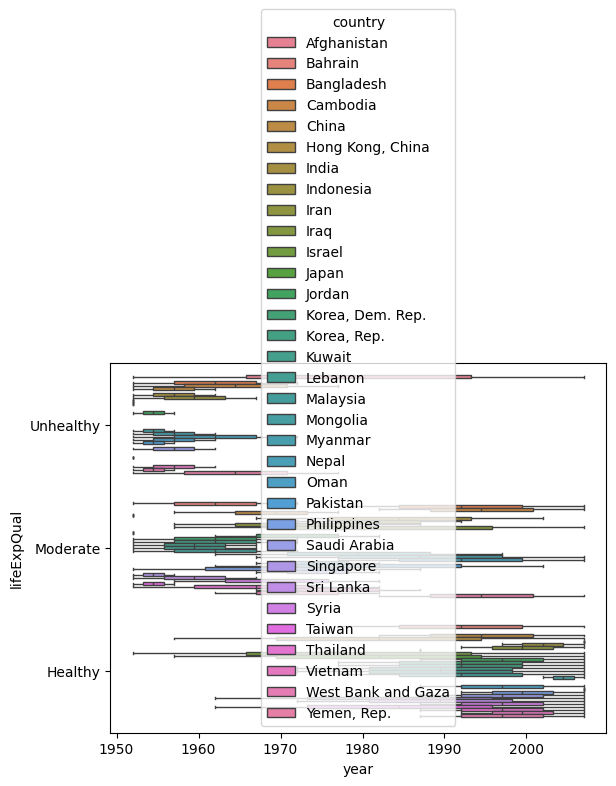

In [42]:
# To do
# Visualize of evolution of lifeExpQual in Asia from 1952 to 2007 using sns.pieplot
data_asia = gapminder[gapminder['continent'] == 'Asia']
data_asia['lifeExpQual'] = pd.cut(data_asia['lifeExp'], bins=3, labels=['Unhealthy', 'Moderate', 'Healthy'])
sns.boxplot(data=data_asia, x='year', y='lifeExpQual', hue='country')

2. Do the same with `popQual` and `dgpQual` columns.

/var/folders/j0/kt7yx7x95r75nsbx5s3ldgt80000gn/T/ipykernel_31999/2939695186.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_asia['PopQual'] = pd.cut(data_asia['pop'], bins=3, labels=['Low', 'Medium', 'High'])


<Axes: xlabel='year', ylabel='PopQual'>

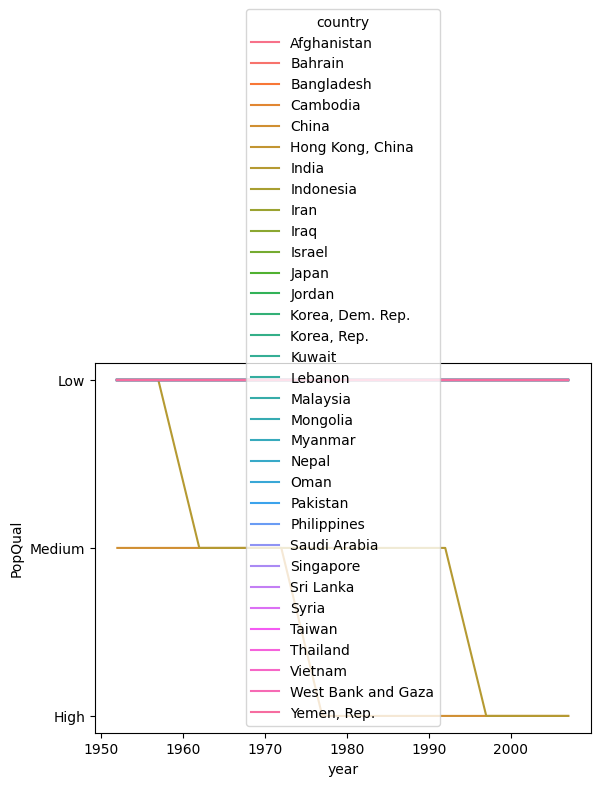

In [38]:
# To do
# Visualize of evolution of PopQual in Asia from 1952 to 2007 using sns.lineplot
data_asia = gapminder[gapminder['continent'] == 'Asia']
data_asia['PopQual'] = pd.cut(data_asia['pop'], bins=3, labels=['Low', 'Medium', 'High'])
sns.lineplot(data=data_asia, x='year', y='PopQual', hue='country')

/var/folders/j0/kt7yx7x95r75nsbx5s3ldgt80000gn/T/ipykernel_31999/2928018107.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_asia['gdpQual'] = pd.cut(data_asia['gdpPercap'], bins=3, labels=['Developing', 'Moderate', 'Developed'])


<Axes: xlabel='year', ylabel='gdpQual'>

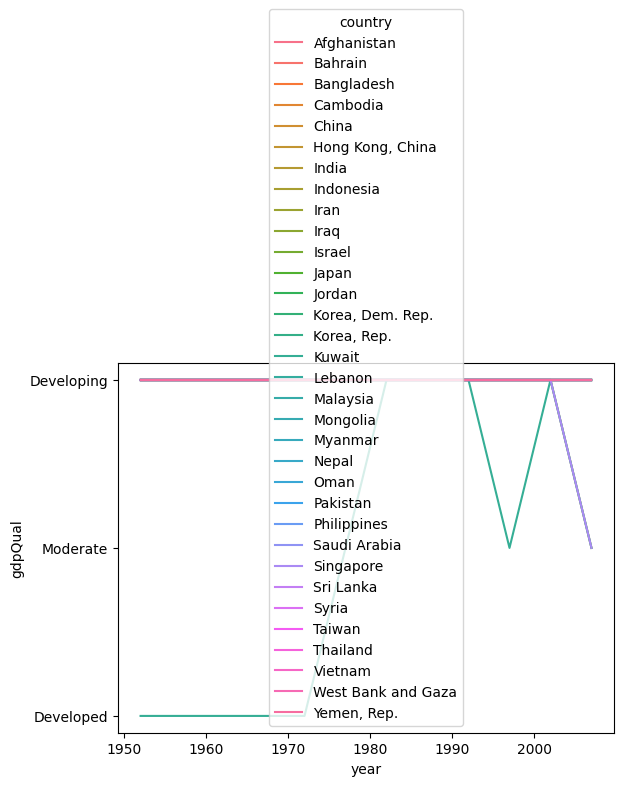

In [39]:
# To do
# To do
# Visualize of evolution of gdpQual in Asia from 1952 to 2007 using sns.lineplot
data_asia = gapminder[gapminder['continent'] == 'Asia']
data_asia['gdpQual'] = pd.cut(data_asia['gdpPercap'], bins=3, labels=['Developing', 'Moderate', 'Developed'])
sns.lineplot(data=data_asia, x='year', y='gdpQual', hue='country')

3. Visualize the evolution of the three qualitative columns above for African countries from 1952 to 2007.

# Further readings
- Gapminder documentation: [https://www.gapminder.org/data/documentation/](https://www.gapminder.org/data/documentation/)
- A short demonstration video is available here: [Hans Rosling's 200 Countries, 200 Years, 4 Minutes - The Joy of Stats - BBC Four](https://youtu.be/jbkSRLYSojo?si=qipg08VIi999hEgo).
- Graphical tools:
    - [`matplotlib`](https://matplotlib.org/stable/index.html)
    - [`seaborn`](https://seaborn.pydata.org/)
    - [`https://plotly.com/python/`](https://plotly.com/python/)